# Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from itertools import product

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

# Visual
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Data

In [ ]:
# Dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset:", data.DESCR.splitlines()[0])
print("X shape:", X.shape)
print("Clases:", np.bincount(y))

# CV estratificada (mismo esquema para todas las combinaciones)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Dataset: .. _breast_cancer_dataset:
X shape: (569, 30)
Clases: [212 357]


# Grid Search

In [ ]:
param_grid = {
    "n_estimators": [50, 100, 200, 400],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

# Número total de combinaciones del grid
N_total = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"])
)
print("Número total de combinaciones en el grid:", N_total)

Número total de combinaciones en el grid: 144


In [ ]:
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    refit=False,              # no necesitamos refit para esta prueba
    return_train_score=False,
    verbose=0
)

grid.fit(X, y)

results = pd.DataFrame(grid.cv_results_)

# Seleccionamos columnas útiles
cols = [
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
]
df = results[cols].copy()

# Ordenar de mejor a peor score
df = df.sort_values(by="mean_test_score", ascending=False).reset_index(drop=True)

In [ ]:
print("Top 10 combinaciones por CV accuracy:")
print(f"\nTotal de filas (combinaciones evaluadas): {len(df)}\n")

df.head(10)

Top 10 combinaciones por CV accuracy:

Total de filas (combinaciones evaluadas): 144



,mean_test_score,std_test_score,rank_test_score,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf
0,0.956094,0.012340,1,100,None,2,1
1,0.956094,0.012340,1,100,20,2,1
2,0.956094,0.012340,1,100,10,2,1
3,0.956094,0.014623,1,100,20,10,2
4,0.956094,0.014623,1,100,10,10,2
5,0.956094,0.014623,1,100,None,10,2
6,0.956078,0.011047,7,200,5,5,1
7,0.956078,0.011047,8,100,5,10,4
8,0.956078,0.011047,8,200,5,2,4
9,0.956078,0.011047,8,200,5,5,4


# Random Search

In [ ]:
# Parámetros del teorema
epsilon_nominal = 0.05   # top 5%
delta = 0.05             # objetivo de confianza 95%

N = len(df)
k_top = math.ceil(epsilon_nominal * N)
epsilon_eff = k_top / N  # probabilidad real en este espacio discreto

print(f"N = {N}")
print(f"epsilon nominal = {epsilon_nominal:.4f}")
print(f"k_top = ceil(epsilon * N) = {k_top}")
print(f"epsilon efectivo = k_top / N = {epsilon_eff:.6f}")
print(f"delta = {delta:.4f}  -> confianza objetivo = {1-delta:.4f}")

def n_min_teorico(epsilon, delta):
    return math.ceil(math.log(1/delta) / math.log(1/(1-epsilon)))

n_star_nominal = n_min_teorico(epsilon_nominal, delta)
n_star_eff = n_min_teorico(epsilon_eff, delta)

print(f"\nn* teórico usando epsilon nominal ({epsilon_nominal:.4f}): {n_star_nominal}")
print(f"n* teórico usando epsilon efectivo ({epsilon_eff:.6f}): {n_star_eff}")

N = 144
epsilon nominal = 0.0500
k_top = ceil(epsilon * N) = 8
epsilon efectivo = k_top / N = 0.055556
delta = 0.0500  -> confianza objetivo = 0.9500

n* teórico usando epsilon nominal (0.0500): 59
n* teórico usando epsilon efectivo (0.055556): 53


Resumen top-ε:
is_top_eps
False    136
True       8
Name: count, dtype: int64


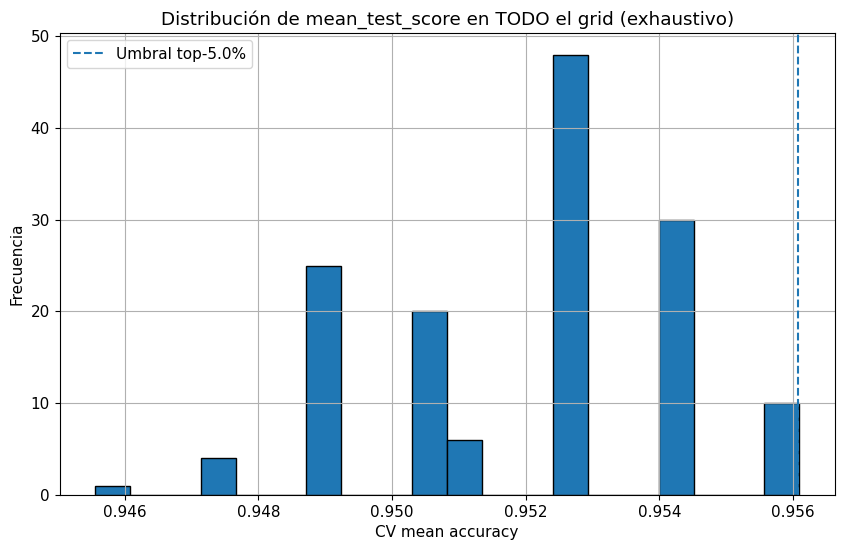

Umbral (score de la posición k=8): 0.956078


In [ ]:
# Definimos el conjunto top-k (mejores k_top combinaciones por score)
df["is_top_eps"] = False
df.loc[:k_top-1, "is_top_eps"] = True

# Resumen
print("Resumen top-ε:")
print(df["is_top_eps"].value_counts())

# Visualizar distribución de scores y umbral del top-k
score_threshold = df.loc[k_top-1, "mean_test_score"]

plt.figure()
plt.hist(df["mean_test_score"], bins=20, edgecolor="black")
plt.axvline(score_threshold, linestyle="--", label=f"Umbral top-{epsilon_nominal*100:.1f}%")
plt.title("Distribución de mean_test_score en TODO el grid (exhaustivo)")
plt.xlabel("CV mean accuracy")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

print(f"Umbral (score de la posición k={k_top}): {score_threshold:.6f}")

In [ ]:
# Máscara booleana del conjunto top-k
top_mask = df["is_top_eps"].to_numpy()
N = len(top_mask)

def prob_exito_teorica(n, epsilon):
    n = np.asarray(n)
    return 1 - (1 - epsilon) ** n

def simular_prob_exito_random_search_sobre_grid(n, top_mask, n_experimentos=10000, replace=True, rng=None):
    """
    Simula random search sobre un espacio discreto finito de N combinaciones.
    Éxito = tocar al menos una combinación del conjunto top-k.

    - replace=True  -> muestreo con reemplazo (coincide con fórmula teórica)
    - replace=False -> muestreo sin reemplazo (prob. de éxito no menor que con reemplazo)
    """
    if rng is None:
        rng = np.random.default_rng()

    N = len(top_mask)
    exitos = np.zeros(n_experimentos, dtype=bool)

    for i in range(n_experimentos):
        idx = rng.choice(N, size=n, replace=replace)
        exitos[i] = top_mask[idx].any()

    return exitos.mean()

def simular_curva(n_values, top_mask, n_experimentos=5000, replace=True, seed=123):
    rng_local = np.random.default_rng(seed)
    probs = []
    for n in n_values:
        probs.append(
            simular_prob_exito_random_search_sobre_grid(
                n=int(n),
                top_mask=top_mask,
                n_experimentos=n_experimentos,
                replace=replace,
                rng=rng_local
            )
        )
    return np.array(probs)

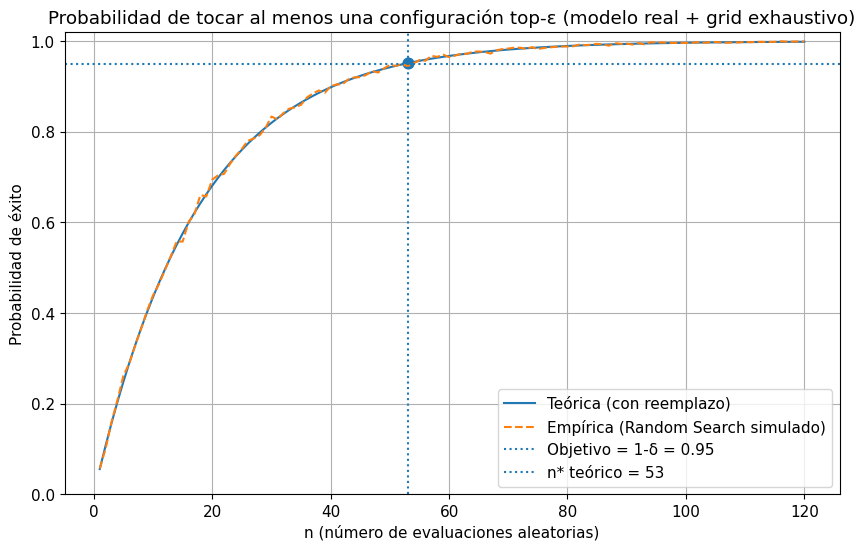

P_teórica(n=52) = 0.948811
P_teórica(n=53)   = 0.951655
Objetivo               = 0.950000


In [ ]:
# Rango de n a evaluar
n_values = np.arange(1, min(120, N) + 1)

# Curva teórica (usar epsilon efectivo porque el top-k es discreto)
p_teo = prob_exito_teorica(n_values, epsilon_eff)

# Simulación empírica (con reemplazo)
p_emp = simular_curva(
    n_values=n_values,
    top_mask=top_mask,
    n_experimentos=4000,
    replace=True,
    seed=2026
)

# Umbral de confianza
objetivo = 1 - delta
n_star = n_star_eff

plt.figure()
plt.plot(n_values, p_teo, label="Teórica (con reemplazo)")
plt.plot(n_values, p_emp, linestyle="--", label="Empírica (Random Search simulado)")
plt.axhline(objetivo, linestyle=":", label=f"Objetivo = 1-δ = {objetivo:.2f}")
plt.axvline(n_star, linestyle=":", label=f"n* teórico = {n_star}")
plt.scatter([n_star], [prob_exito_teorica(n_star, epsilon_eff)], s=60)

plt.title("Probabilidad de tocar al menos una configuración top-ε (modelo real + grid exhaustivo)")
plt.xlabel("n (número de evaluaciones aleatorias)")
plt.ylabel("Probabilidad de éxito")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

print(f"P_teórica(n={n_star-1}) = {prob_exito_teorica(n_star-1, epsilon_eff):.6f}")
print(f"P_teórica(n={n_star})   = {prob_exito_teorica(n_star, epsilon_eff):.6f}")
print(f"Objetivo               = {objetivo:.6f}")

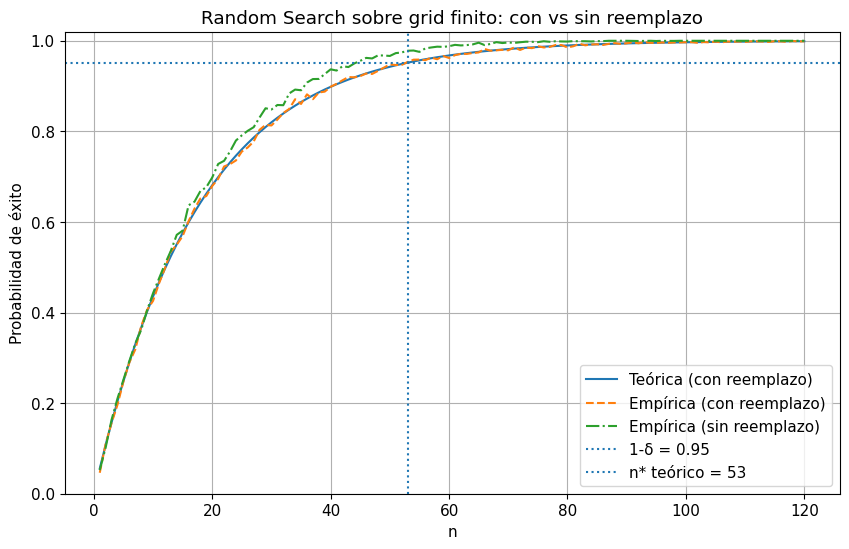

In [ ]:
# Empírico con reemplazo
p_emp_wr = simular_curva(
    n_values=n_values,
    top_mask=top_mask,
    n_experimentos=4000,
    replace=True,
    seed=7
)

# Empírico sin reemplazo
# Ojo: n no puede exceder N sin reemplazo, pero aquí n_values <= min(120, N), así que está ok
p_emp_wor = simular_curva(
    n_values=n_values,
    top_mask=top_mask,
    n_experimentos=4000,
    replace=False,
    seed=8
)

plt.figure()
plt.plot(n_values, p_teo, label="Teórica (con reemplazo)")
plt.plot(n_values, p_emp_wr, linestyle="--", label="Empírica (con reemplazo)")
plt.plot(n_values, p_emp_wor, linestyle="-.", label="Empírica (sin reemplazo)")
plt.axhline(1-delta, linestyle=":", label=f"1-δ = {1-delta:.2f}")
plt.axvline(n_star_eff, linestyle=":", label=f"n* teórico = {n_star_eff}")

plt.title("Random Search sobre grid finito: con vs sin reemplazo")
plt.xlabel("n")
plt.ylabel("Probabilidad de éxito")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

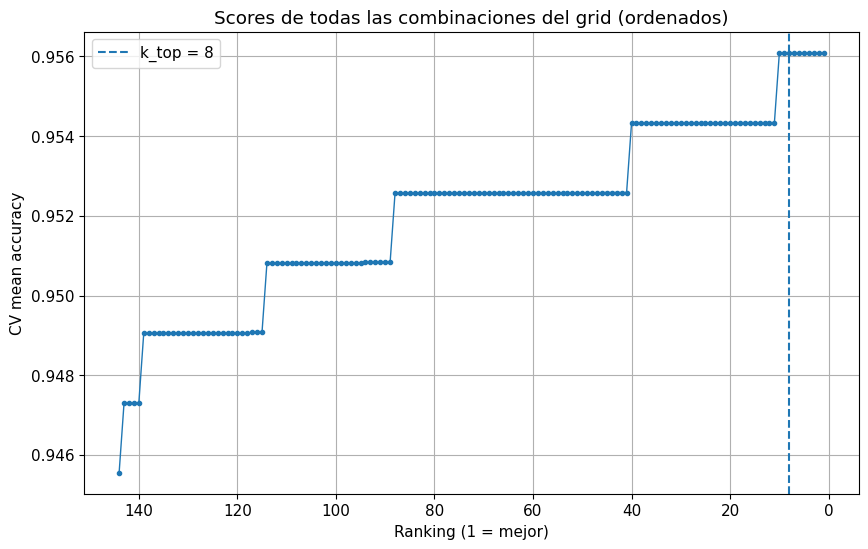

Mejor score del grid        : 0.9560937742586555
Peor score dentro del top-5.0% : 0.9560782487191428
Mediana de todo el grid     : 0.9525694767893185
Peor score del grid         : 0.9455519329296692


In [ ]:
# Curva de scores ordenados
scores_sorted = df["mean_test_score"].to_numpy()

plt.figure()
plt.plot(np.arange(1, N+1), scores_sorted, marker="o", markersize=3, linewidth=1)
plt.axvline(k_top, linestyle="--", label=f"k_top = {k_top}")
plt.gca().invert_xaxis()  # opcional: mejores a la izquierda -> puedes comentar esta línea si no te gusta
plt.title("Scores de todas las combinaciones del grid (ordenados)")
plt.xlabel("Ranking (1 = mejor)")
plt.ylabel("CV mean accuracy")
plt.legend()
plt.show()

print("Mejor score del grid        :", df.loc[0, 'mean_test_score'])
print(f"Peor score dentro del top-{epsilon_nominal*100:.1f}% :", df.loc[k_top-1, 'mean_test_score'])
print("Mediana de todo el grid     :", df['mean_test_score'].median())
print("Peor score del grid         :", df['mean_test_score'].min())

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Importante: en RandomizedSearchCV puedes usar distribuciones o listas.
# Aquí usamos listas discretas para mantener comparabilidad con el grid.
param_distributions = param_grid.copy()

n_iter_demo = n_star_eff  # por ejemplo usar el n* teórico

rand_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=n_iter_demo,
    scoring="accuracy",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=False,
    return_train_score=False,
    verbose=0
)

rand_search.fit(X, y)

df_rand = pd.DataFrame(rand_search.cv_results_).sort_values("mean_test_score", ascending=False).reset_index(drop=True)

print(f"RandomizedSearchCV (n_iter={n_iter_demo}) - top 5 resultados:")
display(df_rand[[
    "mean_test_score",
    "std_test_score",
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
]].head())

RandomizedSearchCV (n_iter=53) - top 5 resultados:


,mean_test_score,std_test_score,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf
0,0.956094,0.012340,100,10,2,1
1,0.956094,0.014623,100,10,10,2
2,0.956078,0.011047,200,5,5,1
3,0.956078,0.011047,200,5,5,4
4,0.956078,0.011047,100,5,10,4


# Conparación


=== TOP-10 GRID SEARCH ===


,rank_grid_topk,mean_test_score,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf
0,1,0.956094,100,None,2,1
1,2,0.956094,100,20,2,1
2,3,0.956094,100,10,2,1
3,4,0.956094,100,20,10,2
4,5,0.956094,100,10,10,2
5,6,0.956094,100,None,10,2
6,7,0.956078,200,5,5,1
7,8,0.956078,100,5,10,4
8,9,0.956078,200,5,2,4
9,10,0.956078,200,5,5,4



=== TOP-10 RANDOM SEARCH ===


,rank_rand_topk,mean_test_score,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf
0,1,0.956094,100,10,2,1
1,2,0.956094,100,10,10,2
2,3,0.956078,200,5,5,1
3,4,0.956078,200,5,5,4
4,5,0.956078,100,5,10,4
5,6,0.954339,50,None,5,1
6,7,0.954339,50,None,2,1
7,8,0.954324,50,5,2,4
8,9,0.954324,400,20,5,1
9,10,0.954324,50,5,5,4



=== Coincidencias exactas entre TOP-10 GRID y TOP-10 RANDOM ===
Coincidencias: 5 / 10


...


=== Cobertura del TOP-10 del GRID por TODO Random Search ===
Cobertura = 5/10 = 50.00%


,rank_grid_topk,mean_test_score,encontrado_por_random,rank_global_en_random,score_en_random,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf
0,1,0.956094,False,NaN,NaN,100,None,2,1
1,2,0.956094,False,NaN,NaN,100,20,2,1
2,3,0.956094,True,1.0,0.956094,100,10,2,1
3,4,0.956094,False,NaN,NaN,100,20,10,2
4,5,0.956094,True,2.0,0.956094,100,10,10,2
5,6,0.956094,False,NaN,NaN,100,None,10,2
6,7,0.956078,True,3.0,0.956078,200,5,5,1
7,8,0.956078,True,5.0,0.956078,100,5,10,4
8,9,0.956078,False,NaN,NaN,200,5,2,4
9,10,0.956078,True,4.0,0.956078,200,5,5,4



=== Configuraciones del TOP-10 del GRID NO encontradas por Random ===


,rank_grid_topk,mean_test_score,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf
0,1,0.956094,100,None,2,1
1,2,0.956094,100,20,2,1
3,4,0.956094,100,20,10,2
5,6,0.956094,100,None,10,2
8,9,0.956078,200,5,2,4



=== Comparación de mejor score ===
Mejor score Grid   : 0.956094
Mejor score Random : 0.956094
Gap (Grid - Random): 0.000000


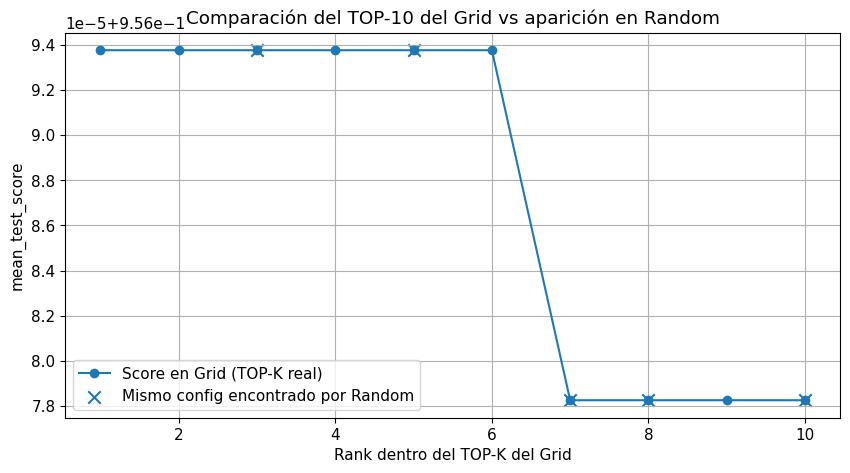


=== Resumen ===


,TOP_K,coincidencias_topk_vs_topk,cobertura_topk_grid_por_random,best_grid_score,best_random_score,gap_grid_minus_random,n_configs_grid,n_configs_random
0,10,5,0.5,0.956094,0.956094,0.0,144,53


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# CONFIGURACIÓN
# =========================
TOP_K = 10  # cambia a 5, 10, 20, etc.

# Columnas de hiperparámetros (ajústalas si cambiaste el modelo/grid)
param_cols = [
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
]

score_col = "mean_test_score"

# =========================
# VALIDACIONES
# =========================
for name, _df in [("df (grid)", df), ("df_rand (random)", df_rand)]:
    faltantes = [c for c in [score_col] + param_cols if c not in _df.columns]
    if faltantes:
        raise ValueError(f"En {name} faltan columnas: {faltantes}")

# Asegurar orden descendente por score
df_grid_sorted = df.sort_values(score_col, ascending=False).reset_index(drop=True).copy()
df_rand_sorted = df_rand.sort_values(score_col, ascending=False).reset_index(drop=True).copy()

# =========================
# FUNCIONES AUXILIARES
# =========================
def normalizar_params(df_in, param_cols):
    """
    Convierte params a strings consistentes para poder comparar filas
    (evita problemas con None, numpy types, etc.)
    """
    df_out = df_in.copy()
    for c in param_cols:
        df_out[c] = df_out[c].astype(str)
    return df_out

def add_param_key(df_in, param_cols, key_name="param_key"):
    """
    Crea una clave única por combinación de hiperparámetros.
    """
    df_out = normalizar_params(df_in, param_cols)
    df_out[key_name] = df_out[param_cols].agg(" | ".join, axis=1)
    return df_out

# Agregar llave de comparación
grid_cmp = add_param_key(df_grid_sorted, param_cols, key_name="param_key")
rand_cmp = add_param_key(df_rand_sorted, param_cols, key_name="param_key")

# Top-K
top_grid = grid_cmp.head(TOP_K).copy()
top_rand = rand_cmp.head(TOP_K).copy()

# Ranking local dentro de cada top
top_grid["rank_grid_topk"] = np.arange(1, len(top_grid) + 1)
top_rand["rank_rand_topk"] = np.arange(1, len(top_rand) + 1)

# =========================
# 1) MOSTRAR TOP-K DE CADA UNO
# =========================
cols_show_grid = ["rank_grid_topk", score_col] + param_cols
cols_show_rand = ["rank_rand_topk", score_col] + param_cols

print(f"\n=== TOP-{TOP_K} GRID SEARCH ===")
display(top_grid[cols_show_grid])

print(f"\n=== TOP-{TOP_K} RANDOM SEARCH ===")
display(top_rand[cols_show_rand])

# =========================
# 2) INTERSECCIÓN EXACTA ENTRE TOP-K GRID Y TOP-K RANDOM
# =========================
inter_topk = top_grid.merge(
    top_rand[["param_key", "rank_rand_topk", score_col] + param_cols].rename(
        columns={score_col: "mean_test_score_random"}
    ),
    on=["param_key"] + param_cols,
    how="inner"
)

inter_topk = inter_topk.rename(columns={score_col: "mean_test_score_grid"})

# Reordenar columnas
if not inter_topk.empty:
    inter_topk = inter_topk[[
        "rank_grid_topk", "rank_rand_topk",
        "mean_test_score_grid", "mean_test_score_random"
    ] + param_cols + ["param_key"]].sort_values(["rank_grid_topk", "rank_rand_topk"])

print(f"\n=== Coincidencias exactas entre TOP-{TOP_K} GRID y TOP-{TOP_K} RANDOM ===")
print(f"Coincidencias: {len(inter_topk)} / {TOP_K}")
display(inter_topk if not inter_topk.empty else pd.DataFrame({"mensaje": ["No hubo coincidencias exactas en el TOP-K"]}))

# =========================
# 3) COBERTURA DEL TOP-K DEL GRID POR TODO EL RANDOM (no solo top-k random)
# =========================
rand_all_keys = set(rand_cmp["param_key"])
top_grid["encontrado_por_random"] = top_grid["param_key"].isin(rand_all_keys)

# Rank global en random (si existe)
rand_global_rank_map = pd.Series(np.arange(1, len(rand_cmp)+1), index=rand_cmp["param_key"]).to_dict()
rand_score_map = rand_cmp.set_index("param_key")[score_col].to_dict()

top_grid["rank_global_en_random"] = top_grid["param_key"].map(rand_global_rank_map)
top_grid["score_en_random"] = top_grid["param_key"].map(rand_score_map)

cobertura = top_grid["encontrado_por_random"].mean()

print(f"\n=== Cobertura del TOP-{TOP_K} del GRID por TODO Random Search ===")
print(f"Cobertura = {top_grid['encontrado_por_random'].sum()}/{TOP_K} = {cobertura:.2%}")

display(top_grid[[
    "rank_grid_topk", score_col, "encontrado_por_random", "rank_global_en_random", "score_en_random"
] + param_cols])

# =========================
# 4) CONFIGURACIONES TOP DEL GRID QUE RANDOM NO ENCONTRÓ
# =========================
no_encontradas = top_grid.loc[~top_grid["encontrado_por_random"], ["rank_grid_topk", score_col] + param_cols]

print(f"\n=== Configuraciones del TOP-{TOP_K} del GRID NO encontradas por Random ===")
display(no_encontradas if not no_encontradas.empty else pd.DataFrame({"mensaje": ["Random encontró todas las del TOP-K del Grid"]}))

# =========================
# 5) COMPARAR LOS MEJORES SCORES ALCANZADOS
# =========================
best_grid_score = grid_cmp[score_col].max()
best_rand_score = rand_cmp[score_col].max()
gap = best_grid_score - best_rand_score

print("\n=== Comparación de mejor score ===")
print(f"Mejor score Grid   : {best_grid_score:.6f}")
print(f"Mejor score Random : {best_rand_score:.6f}")
print(f"Gap (Grid - Random): {gap:.6f}")

# =========================
# 6) GRÁFICO: TOP-K GRID vs score obtenido por random (si lo encontró)
# =========================
plot_df = top_grid.copy()

plt.figure(figsize=(10, 5))
plt.plot(plot_df["rank_grid_topk"], plot_df[score_col], marker="o", label="Score en Grid (TOP-K real)")

# Solo puntos encontrados por random
mask_found = plot_df["score_en_random"].notna()
if mask_found.any():
    plt.scatter(
        plot_df.loc[mask_found, "rank_grid_topk"],
        plot_df.loc[mask_found, "score_en_random"],
        marker="x",
        s=80,
        label="Mismo config encontrado por Random"
    )

plt.title(f"Comparación del TOP-{TOP_K} del Grid vs aparición en Random")
plt.xlabel("Rank dentro del TOP-K del Grid")
plt.ylabel("mean_test_score")
plt.legend()
plt.grid(True)
plt.show()

# =========================
# 7) (OPCIONAL) TABLA RESUMEN FINAL
# =========================
resumen = pd.DataFrame({
    "TOP_K": [TOP_K],
    "coincidencias_topk_vs_topk": [len(inter_topk)],
    "cobertura_topk_grid_por_random": [cobertura],
    "best_grid_score": [best_grid_score],
    "best_random_score": [best_rand_score],
    "gap_grid_minus_random": [gap],
    "n_configs_grid": [len(grid_cmp)],
    "n_configs_random": [len(rand_cmp)],
})

print("\n=== Resumen ===")
display(resumen)